#LangGraph - Persistance, Checkpointers & Threads

##Setup

In [ ]:
!pip install langgraph langchain_core langchain_groq

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 589.8/589.8 kB 5.6 MB/s  0:00:00
  Attempting uninstall: langchain_core
    Found existing installation: langchain-core 1.7.4
    Uninstalling langchain-core-1.7.4:
      Successfully uninstalled langchain-core-1.7.4
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [langchain_groq]


In [ ]:
!pip install grandalf

In [ ]:
# Set Groq API token
# In Prod should be done through .env files
import os
os.environ['GROQ_API_KEY'] = "<YOUR API KEY HERE>"

## Persistance and Checkpointer

02-checkpoint-every-node.svg

### What each Checkpoint consists of

03-checkpoint-anatomy.svg

### What are threads in checkpoints?

04-threads.svg

In [ ]:
# If we want to Fail the graph
FAIL_WORKFLOW = False

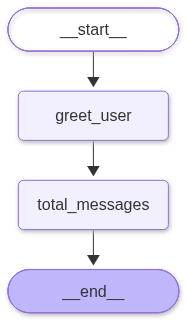

In [ ]:
# Example Graph
from typing import TypedDict, Annotated
from langgraph.graph.message import add_messages
from langchain_groq import ChatGroq
from langgraph.graph import StateGraph, START, END
from langchain_core.messages import HumanMessage, AIMessage
from langgraph.checkpoint.memory import InMemorySaver

# State
class CustomState(TypedDict):
  messages: Annotated[list, add_messages]
  total_messages: int

# Greet Node
def greet_node(state: CustomState):
  _chat = ChatGroq(
      model = "openai/gpt-oss-20b",
      max_tokens = 1000,
      temperature = 0
  )
  _output = _chat.invoke([{"role":"system", "content": "Identify the User from the Conversation. Always Greet first before answering question in Specified format only. If you already know from Past conversation greet in format : Welcome back [user] else : Hello [user], and then answer the question"}] + state['messages']).content
  return {'messages': [AIMessage(_output)]}

# Count Total Messages in the Conversation Node
def total_messages(state: CustomState):
  if FAIL_WORKFLOW:
    raise Exception("Failed")

  return {'total_messages': len(state['messages'])}

# Build graph Nodes and Edges
builder = StateGraph(CustomState)
builder.add_node("greet_user", greet_node)
builder.add_node("total_messages", total_messages)

builder.add_edge(START, "greet_user")
builder.add_edge("greet_user", "total_messages")
builder.add_edge("total_messages", END)

# Compile
graph = builder.compile(checkpointer=InMemorySaver())
graph

In [ ]:
# Invoke
initial_state = {"messages": "My Name is Subham, I like Veg food", "total_messages":0}
config = {"configurable": {"thread_id" : "abc123"}}

output = graph.invoke(initial_state, config=config)
print(output['messages'][-1])



content='Hello Subham,\n\nNice to meet you! I see you enjoy veg food. How can I help you today?' additional_kwargs={} response_metadata={} id='85b04360-59bf-4f17-8f55-fd60928a9e85' tool_calls=[] invalid_tool_calls=[]


In [ ]:
# Invoke
initial_state = {"messages": "What is my Name and What I Like ?", "total_messages":0}
config = {"configurable": {"thread_id" : "abc123"}}

output = graph.invoke(initial_state, config=config)
print(output['total_messages'], output['messages'][-1])


10 content='Welcome back Subham.  \nYour name is Subham, and you like veg food.' additional_kwargs={} response_metadata={} id='288a55e6-751d-41d6-b804-3a9f3829ff24' tool_calls=[] invalid_tool_calls=[]


In [24]:
FAIL_WORKFLOW = False

In [26]:
snapshot = graph.get_state(config)
snapshot.next

('total_messages',)

In [27]:
initial_state = {"messages": "My name is Subham", "total_messages":0}
config = {"configurable": {"thread_id" : "efg123"}}

for state in graph.stream(None, config=config, stream_mode="updates"):
  print(state)

{'total_messages': {'total_messages': 2}}
